In [2]:
# import libraries
import malariagen_data
af1 = malariagen_data.Af1()
af1

<MalariaGEN Af1 API client>
Storage URL                           : gs://vo_afun_release_master_us_central1/
Data releases available               : 1.0, 1.1, 1.2, 1.3, 1.4
Results cache                         : None
Cohorts analysis                      : 20240515
Site filters analysis                 : dt_20200416
Software version                      : malariagen_data 15.5.0
Client location                       : Banjul, Gambia
Data filtered to unrestricted use only: False
Data filtered to surveillance use only: False
Relevant data releases                : 1.0, 1.1, 1.2, 1.3, 1.4
---
Please note that data are subject to terms of use,
for more information see https://www.malariagen.net/data
or contact support@malariagen.net. For API documentation see 
https://malariagen.github.io/malariagen-data-python/v15.5.0/Af1.html

In [3]:
# importing other necessary libraries

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import matplotlib.cm as cm
from matplotlib.patches import Patch
import numpy as np
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings("ignore")


In [3]:
# for plots
sns.set_style('white')
sns.set_style('ticks')
sns.set_context('notebook')
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

In [4]:
# This projects works on malariagen data from the GSM2 project that has sample from Senega;l, Guinea, Nigeria, Cameroon and Kenya 
# with one sample in Mali and 2 in Tanzania
#list of the most representatives set of samples

sample_sets = ['1188-VO-NIANG-NIEL-SN-2304-VMF00259', '1330-VO-GN-LAMA-VMF00250',
                  '1315-VO-NG-OMITOLA-OMOL-NG-2008',
                  '1281-VO-CM-CHRISTOPHE-VMF00227', 'AG1000G-KE']

df_samples = af1.sample_metadata(sample_sets=sample_sets, sample_query='taxon == "funestus"')
df_samples

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
0,VBS84387-6020STDY14423812,NIEL_002_G4,El Hadji Amadou Niang,Senegal,SARE YOUSSOUPH,2020,7,12.832,-15.005,F,...,Kolda,SN-KD,Kolda,funestus,SN-KD_fune_2020,SN-KD_fune_2020_07,SN-KD_fune_2020_Q3,SN-KD_Kolda_fune_2020,SN-KD_Kolda_fune_2020_07,SN-KD_Kolda_fune_2020_Q3
1,VBS84393-6020STDY14423818,NIEL_002_E5,El Hadji Amadou Niang,Senegal,SARE YOUSSOUPH,2020,7,12.832,-15.005,F,...,Kolda,SN-KD,Kolda,funestus,SN-KD_fune_2020,SN-KD_fune_2020_07,SN-KD_fune_2020_Q3,SN-KD_Kolda_fune_2020,SN-KD_Kolda_fune_2020_07,SN-KD_Kolda_fune_2020_Q3
2,VBS84394-6020STDY14423819,NIEL_002_F5,El Hadji Amadou Niang,Senegal,SARE YOUSSOUPH,2020,7,12.832,-15.005,F,...,Kolda,SN-KD,Kolda,funestus,SN-KD_fune_2020,SN-KD_fune_2020_07,SN-KD_fune_2020_Q3,SN-KD_Kolda_fune_2020,SN-KD_Kolda_fune_2020_07,SN-KD_Kolda_fune_2020_Q3
3,VBS84409-6020STDY14423834,NIEL_002_E7,El Hadji Amadou Niang,Senegal,SARE YOUSSOUPH,2020,7,12.832,-15.005,F,...,Kolda,SN-KD,Kolda,funestus,SN-KD_fune_2020,SN-KD_fune_2020_07,SN-KD_fune_2020_Q3,SN-KD_Kolda_fune_2020,SN-KD_Kolda_fune_2020_07,SN-KD_Kolda_fune_2020_Q3
4,VBS84417-6020STDY14423842,NIEL_002_E8,El Hadji Amadou Niang,Senegal,SARE YOUSSOUPH,2020,7,12.832,-15.005,F,...,Kolda,SN-KD,Kolda,funestus,SN-KD_fune_2020,SN-KD_fune_2020_07,SN-KD_fune_2020_Q3,SN-KD_Kolda_fune_2020,SN-KD_Kolda_fune_2020_07,SN-KD_Kolda_fune_2020_Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
630,AK0161-C,KIL120,Janet Midega,Kenya,Kilifi,2012,-1,-3.511,39.909,F,...,Kilifi,KE-14,Kilifi North,funestus,KE-14_fune_2012,KE-14_fune_2012,KE-14_fune_2012,KE-14_Kilifi-North_fune_2012,KE-14_Kilifi-North_fune_2012,KE-14_Kilifi-North_fune_2012
631,AK0163-C,KIL122,Janet Midega,Kenya,Kilifi,2012,-1,-3.511,39.909,F,...,Kilifi,KE-14,Kilifi North,funestus,KE-14_fune_2012,KE-14_fune_2012,KE-14_fune_2012,KE-14_Kilifi-North_fune_2012,KE-14_Kilifi-North_fune_2012,KE-14_Kilifi-North_fune_2012
632,AK0164-C,KIL123,Janet Midega,Kenya,Kilifi,2012,-1,-3.511,39.909,F,...,Kilifi,KE-14,Kilifi North,funestus,KE-14_fune_2012,KE-14_fune_2012,KE-14_fune_2012,KE-14_Kilifi-North_fune_2012,KE-14_Kilifi-North_fune_2012,KE-14_Kilifi-North_fune_2012
633,AK0165-C,KIL124,Janet Midega,Kenya,Kilifi,2012,-1,-3.511,39.909,F,...,Kilifi,KE-14,Kilifi North,funestus,KE-14_fune_2012,KE-14_fune_2012,KE-14_fune_2012,KE-14_Kilifi-North_fune_2012,KE-14_Kilifi-North_fune_2012,KE-14_Kilifi-North_fune_2012


In [6]:
pivot_year_sample_sets = (
    df_samples
    .pivot_table(
        index=["sample_set", "year", "month", "country", "admin1_name", "latitude", "longitude"],
        columns=["taxon"],
        values="sample_id",
        aggfunc="count",
        fill_value=0,
    )
)
pivot_year_sample_sets.reset_index(inplace=True)
pivot_year_sample_sets

taxon,sample_set,year,month,country,admin1_name,latitude,longitude,funestus
0,1188-VO-NIANG-NIEL-SN-2304-VMF00259,2020,7,Senegal,Kaolack,13.784,-16.190,1
1,1188-VO-NIANG-NIEL-SN-2304-VMF00259,2020,7,Senegal,Kedougou,12.553,-12.529,4
2,1188-VO-NIANG-NIEL-SN-2304-VMF00259,2020,7,Senegal,Kedougou,12.623,-11.610,1
3,1188-VO-NIANG-NIEL-SN-2304-VMF00259,2020,7,Senegal,Kolda,12.832,-15.005,5
4,1188-VO-NIANG-NIEL-SN-2304-VMF00259,2021,9,Senegal,Kolda,12.832,-15.005,16
5,1188-VO-NIANG-NIEL-SN-2304-VMF00259,2022,10,Senegal,Kolda,12.832,-15.005,19
6,1188-VO-NIANG-NIEL-SN-2304-VMF00259,2022,10,Senegal,Louga,15.953,-15.921,13
7,1188-VO-NIANG-NIEL-SN-2304-VMF00259,2022,10,Senegal,Saint Louis,16.325,-15.767,1
8,1188-VO-NIANG-NIEL-SN-2304-VMF00259,2022,10,Senegal,Saint Louis,16.542,-14.801,11
9,1281-VO-CM-CHRISTOPHE-VMF00227,2020,9,Cameroon,South,2.821,10.135,81


In [6]:
pivot_year_sample_sets.to_csv('sample_admin1.csv')

In [7]:
pivot_sample_sets = (
    df_samples
    .pivot_table(
        index=["sample_set", "country", "admin1_name"],
        columns=["taxon"],
        values="sample_id",
        aggfunc="count",
        fill_value=0,
    )
)
pivot_sample_sets
pivot_sample_sets.to_csv('sample_sets_country.csv')

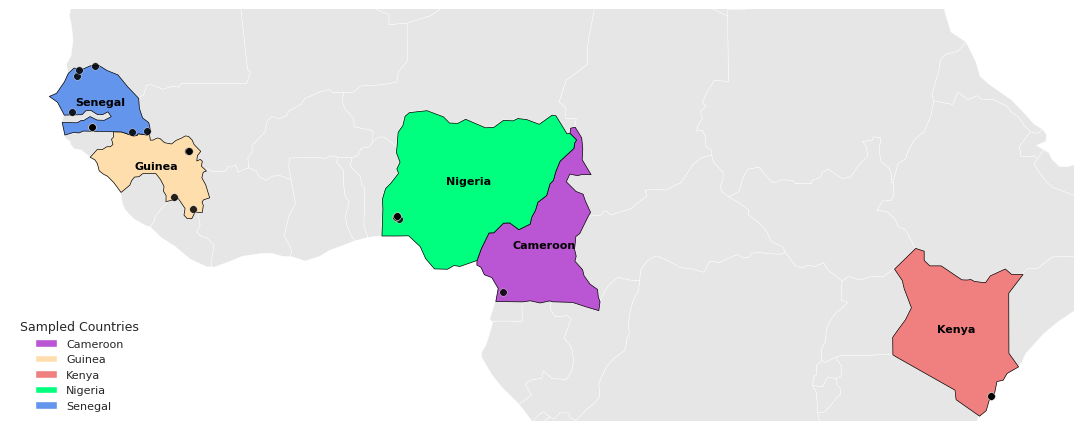

In [9]:
# Load Africa shapefile

world = gpd.read_file("/home/mrc.gm/hsaizonou/ne_admin0/ne_110m_admin_0_countries.shp")
africa = world[world["CONTINENT"] == "Africa"].copy()

# Load sample metadata (contains: country, lat, lon, site_name, etc.)
samples = pivot_year_sample_sets

# Clean and ensure coordinates exist
samples = samples.dropna(subset=["latitude", "longitude", "country"])

# Create geometry
samples["geometry"] = samples.apply(lambda r: Point(r["longitude"], r["latitude"]), axis=1)
gdf_samples = gpd.GeoDataFrame(samples, geometry="geometry", crs="EPSG:4326")

# Identify countries that have samples
sample_countries = sorted(gdf_samples["country"].unique())

# Assign colors per sample country
colors_country = {
    "Senegal": "cornflowerblue",
    "Guinea": "navajowhite",
    "Nigeria": "springgreen",
    "Cameroon": "mediumorchid",
    "Kenya": "lightcoral",
}
# Extract polygons only for sampled countries
africa_samples = africa[africa["NAME"].isin(sample_countries)].copy()

# Plotting
fig, ax = plt.subplots(figsize=(11, 8))

# Base map: whole Africa in light grey
africa.plot(ax=ax, color="#e6e6e6", edgecolor="white", linewidth=0.3)

# Highlight sampled countries
for country in sample_countries:
    subset = africa_samples[africa_samples["NAME"] == country]
    subset.plot(
        ax=ax,
        color=colors_country[country],
        edgecolor="black",
        linewidth=0.5
    )

# Plot sample points on top
gdf_samples.plot(
    ax=ax,
    markersize=30,
    color="black",
    edgecolor="white",
    linewidth=0.3,
    alpha=0.85
)

# Labels: place country names at centroid
for _, row in africa_samples.iterrows():
    cx = row.geometry.centroid.x
    cy = row.geometry.centroid.y

    ax.text(
        cx,
        cy,
        row["NAME"],
        ha="center",
        va="center",
        fontsize=8,
        color="black",
        weight="bold"
    )

# Adjust map extent
ax.set_xlim(-20, 45)
ax.set_ylim(-5, 20)
ax.set_axis_off()

# Legend for country colours
handles = [
    Patch(facecolor=colors_country[c], label=c)
    for c in sample_countries
]

ax.legend(
    handles=handles,
    title="Sampled Countries",
    frameon=False,
    loc="lower left",
    fontsize=8,
    title_fontsize=9
)

plt.tight_layout()
plt.savefig("sample_collection_map.png", dpi=500, bbox_inches="tight")
plt.show()


In [5]:
pivot_year_sample = (
    df_samples
    .pivot_table(
        index=["sample_set", "country", "admin1_name", "latitude", "longitude"],
        columns=["taxon"],
        values="sample_id",
        aggfunc="count",
        fill_value=0,
    )
)
pivot_year_sample

taxon                                                                        funestus
sample_set                          country  admin1_name latitude longitude          
1188-VO-NIANG-NIEL-SN-2304-VMF00259 Senegal  Kaolack      13.784  -16.190           1
                                             Kedougou     12.553  -12.529           4
                                                          12.623  -11.610           1
                                             Kolda        12.832  -15.005          40
                                             Louga        15.953  -15.921          13
                                             Saint Louis  16.325  -15.767           1
                                                          16.542  -14.801          11
1281-VO-CM-CHRISTOPHE-VMF00227      Cameroon South        2.821    10.135          81
1315-VO-NG-OMITOLA-OMOL-NG-2008     Nigeria  Ogun         7.235    3.749           20
                                                          7.361    3.600          105
                                                          7.420    3.640          111
                                             Oyo          7.445    3.633           27
1330-VO-GN-LAMA-VMF00250            Guinea   Kankan       11.370  -9.150            7
                                                          11.416  -9.058            6
                                             Nzerekore    7.846   -8.846           88
                                                          8.591   -9.959           95
AG1000G-KE                          Kenya    Kilifi      -3.511    39.909          24

In [6]:
pivot_year_sample.to_csv('pivot_year_sample.csv')

✓ Saved → sample_collection_map_v10.png


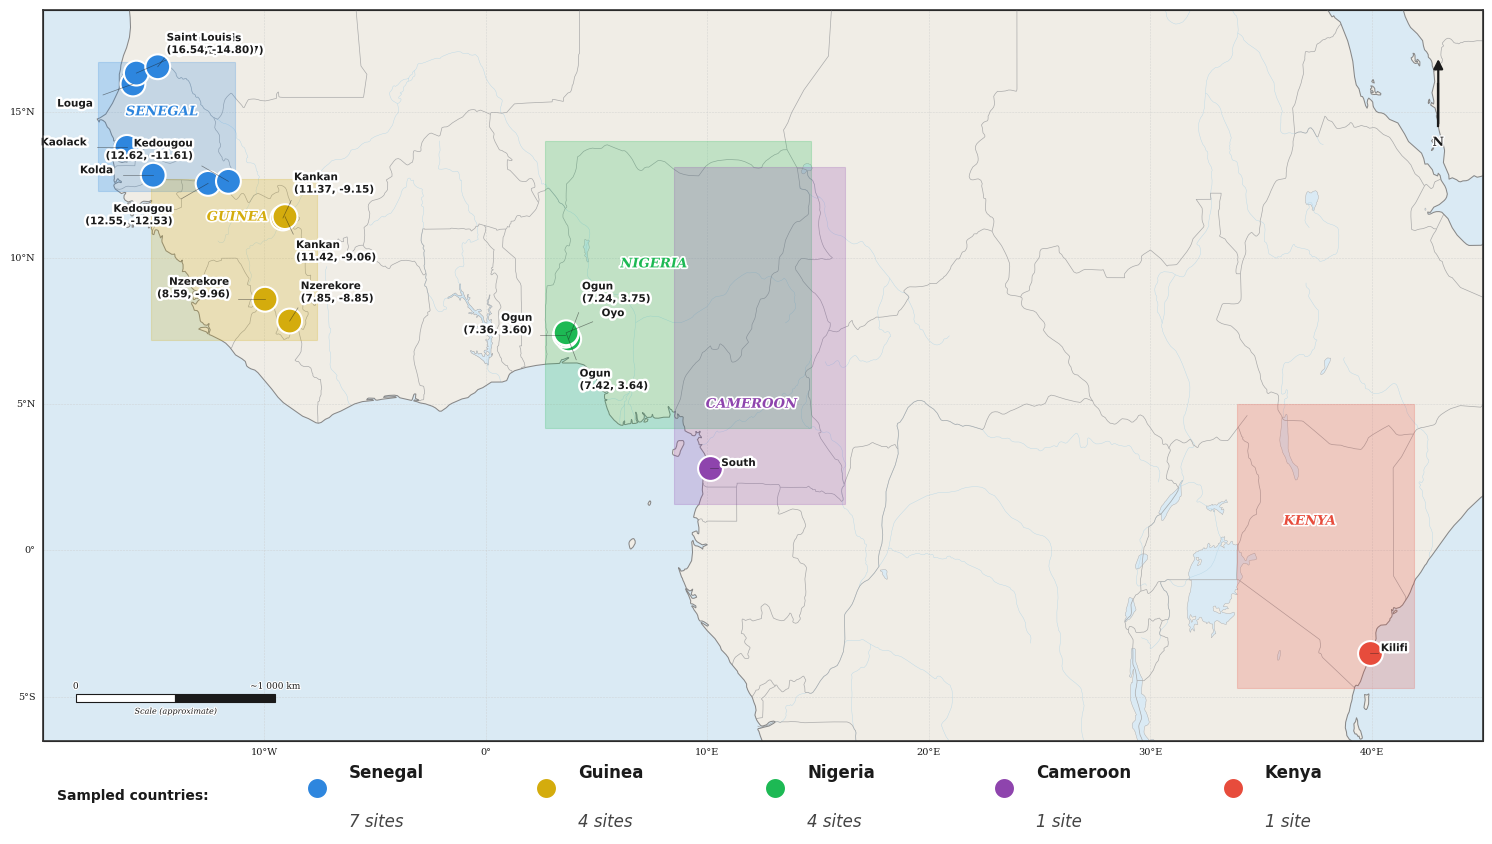

In [16]:
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False
    print("cartopy not found – falling back to plain matplotlib axes.")


df = pd.read_csv("pivot_year_sample.csv")

sites = (
    df[["country", "admin1_name", "latitude", "longitude"]]
      .drop_duplicates()
      .reset_index(drop=True)
)

# Fixed bubble size — larger for visibility
sites["size"] = 320

COUNTRY_COLORS = {
    "Senegal":  "#2E86DE",   # vivid blue
    "Guinea":   "#D4AC0D",   # strong gold
    "Nigeria":  "#1DB954",   # vivid green
    "Cameroon": "#8E44AD",   # bright purple
    "Kenya":    "#E74C3C",   # strong red
}

WHITE      = "#FFFFFF"
OCEAN_COL  = "#DAEAF4"
LAND_COL   = "#F0EDE6"
BORDER_COL = "#AAAAAA"
GRID_COL   = "#CCCCCC"
INK        = "#1A1A1A"


LABEL_OFFSETS = {
    # ── Senegal ──────────────────────────────────────────────────────────────
    # Saint Louis pair: one goes far right+up, other far right+down
    ("Saint Louis", 16.325, -15.767): ( 1.8,  0.6),   # western SL  → right + up
    ("Saint Louis", 16.52, -14.801): ( 0.6, -0.7),   # eastern SL  → right + down
    # Louga: push LEFT so it doesn't clash with Saint Louis above it
    ("Louga",       15.953, -15.921): (-1.8, -0.5),
    ("Kaolack",     13.784, -16.19 ): (-1.8,  0.0),
    ("Kolda",       12.832, -15.005): (-1.8,  0.0),
    # Kedougou pair: fan up and down, away from Kankan (which is to the right)
    ("Kedougou",    12.553, -12.529): (-1.6, -0.7),
    ("Kedougou",    12.623, -11.61 ): (-1.6,  0.7),
    # ── Guinea ───────────────────────────────────────────────────────────────
    # Kankan: push LEFT + down to stay clear of Kedougou
    ("Kankan",      11.37,  -9.15  ): ( 0.5,  0.8),
    ("Kankan",      11.416, -9.058 ): ( 0.5, -0.8),
    # Nzerekore pair: fan left and right
    ("Nzerekore",    7.846, -8.846 ): ( 0.5,  0.6),
    ("Nzerekore",    8.591, -9.959 ): (-1.6,  0.0),
    # ── Nigeria ──────────────────────────────────────────────────────────────
    # Ogun (3 dots very close together): fan strongly in 3 directions
    ("Ogun",         7.235,  3.749 ): ( 0.6,  1.2),   # northernmost → up
    ("Ogun",         7.361,  3.6   ): (-1.5,  0.0),   # middle       → left
    ("Ogun",         7.42,   3.64  ): ( 0.6, -1.2),   # southernmost → down
    # Oyo: push far LEFT to avoid the Ogun cluster entirely
    ("Oyo",          7.445,  3.633 ): ( 1.6,  0.5),
    # ── Cameroon / Kenya ─────────────────────────────────────────────────────
    ("South",        2.821, 10.135 ): ( 0.5,  0.0),
    ("Kilifi",      -3.511, 39.909 ): ( 0.5,  0.0),
}

COUNTRY_LABEL_POS = {
    "Senegal":  (-14.6, 15.0),
    "Guinea":   (-11.2, 11.4),
    "Nigeria":  (  7.6,  9.8),
    "Cameroon": ( 12.0,  5.0),
    "Kenya":    ( 37.2,  1.0),
}

country_bounds = {
    "Senegal":  (-17.5, -11.3, 12.3, 16.7),
    "Guinea":   (-15.1,  -7.6,  7.2, 12.7),
    "Nigeria":  (  2.7,  14.7,  4.2, 14.0),
    "Cameroon": (  8.5,  16.2,  1.6, 13.1),
    "Kenya":    ( 33.9,  41.9, -4.7,  5.0),
}

FIG_W, FIG_H = 15, 8.5
fig = plt.figure(figsize=(FIG_W, FIG_H), facecolor=WHITE)

# Map: starts near bottom (legend rows are tight), top clipped to data extent
MAP_L, MAP_B, MAP_W, MAP_H = 0.02, 0.14, 0.96, 0.86

# ── Map axes ──────────────────────────────────────────────────────────────────
if HAS_CARTOPY:
    proj = ccrs.PlateCarree()
    ax = fig.add_axes([MAP_L, MAP_B, MAP_W, MAP_H], projection=proj)
    ax.set_extent([-20, 45, -6.5, 18.5], crs=proj)
    ax.set_aspect("auto")   # fill axes box exactly — no internal whitespace
    ax.set_facecolor(OCEAN_COL)
    ax.add_feature(cfeature.LAND,      facecolor=LAND_COL,   zorder=1)
    ax.add_feature(cfeature.OCEAN,     facecolor=OCEAN_COL,  zorder=0)
    ax.add_feature(cfeature.BORDERS,   linewidth=0.5,  edgecolor=BORDER_COL, zorder=3)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.75, edgecolor="#888888",  zorder=3)
    ax.add_feature(cfeature.LAKES,     facecolor=OCEAN_COL,
                   edgecolor=BORDER_COL, linewidth=0.3, zorder=2)
    ax.add_feature(cfeature.RIVERS,    linewidth=0.3, edgecolor="#B8D8E8", zorder=2)
    gl = ax.gridlines(crs=proj, draw_labels=True, linewidth=0.4,
                      color=GRID_COL, alpha=0.7, linestyle="--",
                      x_inline=False, y_inline=False)
    gl.top_labels = False; gl.right_labels = False
    gl.xformatter = LONGITUDE_FORMATTER; gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {"size": 7, "color": INK, "family": "serif"}
    gl.ylabel_style = {"size": 7, "color": INK, "family": "serif"}
    gl.xlocator = mticker.MultipleLocator(10)
    gl.ylocator = mticker.MultipleLocator(5)
    transform = proj
else:
    ax = fig.add_axes([MAP_L, MAP_B, MAP_W, MAP_H])
    ax.set_xlim(-20, 45); ax.set_ylim(-6.5, 18.5)
    ax.set_facecolor(OCEAN_COL)
    ax.tick_params(labelsize=7, colors=INK)
    transform = None

# Country wash
for country, (lon0, lon1, lat0, lat1) in country_bounds.items():
    col = COUNTRY_COLORS[country]
    kw = dict(linewidth=0.8, edgecolor=col, facecolor=col, alpha=0.22, zorder=4)
    if HAS_CARTOPY: kw["transform"] = transform
    ax.add_patch(mpatches.Rectangle((lon0, lat0), lon1-lon0, lat1-lat0, **kw))

# Bubbles
for country, grp in sites.groupby("country"):
    col = COUNTRY_COLORS.get(country, "#888888")
    kw = dict(x=grp["longitude"], y=grp["latitude"],
              s=grp["size"], c=col, alpha=1.0,
              edgecolors="white", linewidths=1.5, zorder=6)
    if HAS_CARTOPY:
        ax.scatter(**kw, transform=transform)
    else:
        ax.scatter(**kw)

# Count how many times each admin name appears (to flag duplicates)
admin_counts = sites["admin1_name"].value_counts()

# Admin labels + connectors
for _, row in sites.iterrows():
    la0 = round(float(row["latitude"]),  3)
    lo0 = round(float(row["longitude"]), 3)
    key = (row["admin1_name"], la0, lo0)
    dlon, dlat = LABEL_OFFSETS.get(key, (0.4, 0.4))

    # For duplicate admin names, append short coords to disambiguate
    if admin_counts[row["admin1_name"]] > 1:
        label = f"{row['admin1_name']}\n({la0:.2f}, {lo0:.2f})"
    else:
        label = row["admin1_name"]

    lo_txt = lo0 + dlon
    la_txt = la0 + dlat
    kw = dict(s=label, fontsize=7.5, fontfamily="sans-serif",
              fontweight="bold", color=INK,
              ha="left" if dlon >= 0 else "right",
              va="bottom" if dlat >= 0 else "top", zorder=8,
              linespacing=1.3,
              path_effects=[pe.withStroke(linewidth=3.5, foreground=WHITE)])
    if HAS_CARTOPY: ax.text(lo_txt, la_txt, transform=transform, **kw)
    else:           ax.text(lo_txt, la_txt, **kw)

    # Connector line from dot to label
    lo1, la1 = lo0 + dlon * 0.75, la0 + dlat * 0.75
    kw2 = dict(color=INK, lw=0.5, alpha=0.5, zorder=7)
    if HAS_CARTOPY: ax.plot([lo0, lo1], [la0, la1], transform=transform, **kw2)
    else:           ax.plot([lo0, lo1], [la0, la1], **kw2)

# Country name labels
for country, (lon, lat) in COUNTRY_LABEL_POS.items():
    col = COUNTRY_COLORS[country]
    kw = dict(s=country.upper(), fontsize=9.5, fontweight="bold",
              fontstyle="italic", fontfamily="serif", color=col,
              ha="center", va="center", zorder=9,
              path_effects=[pe.withStroke(linewidth=2.5, foreground=WHITE)])
    if HAS_CARTOPY: ax.text(lon, lat, transform=transform, **kw)
    else:           ax.text(lon, lat, **kw)

def draw_north_arrow_data(ax, lon, lat, size=2.0, transform=None):
    """Draw a north arrow at (lon, lat) in data / map coordinates."""
    kw = {"zorder": 20}
    if transform: kw["transform"] = transform

    # Arrow shaft + head
    ax.annotate(
        "", xy=(lon, lat + size * 0.75), xytext=(lon, lat),
        xycoords=transform if transform else "data",
        textcoords=transform if transform else "data",
        arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.6,
                        mutation_scale=14),
        **{"zorder": 20}
    )
    ax.plot([lon, lon], [lat, lat + size * 0.45],
            color=INK, lw=1.6, zorder=20,
            **({} if not transform else {"transform": transform}))

    # "N" label below the tail
    kw_txt = dict(fontsize=9, fontweight="bold", fontfamily="serif",
                  color=INK, ha="center", va="top", zorder=20,
                  path_effects=[pe.withStroke(linewidth=2, foreground=WHITE)])
    if transform:
        ax.text(lon, lat - size * 0.1, "N", transform=transform, **kw_txt)
    else:
        ax.text(lon, lat - size * 0.1, "N", **kw_txt)

draw_north_arrow_data(ax, lon=43.0, lat=14.5, size=3.2, transform=transform)


x0_bar, x1_bar = -18.5, -18.5 + 9.0
y_bar, bar_h = -5.2, 0.28
xm = (x0_bar + x1_bar) / 2

for patch_x, patch_col in [(x0_bar, WHITE), (xm, INK)]:
    kw = dict(facecolor=patch_col, edgecolor=INK, linewidth=0.8, zorder=12)
    if HAS_CARTOPY: kw["transform"] = transform
    ax.add_patch(mpatches.Rectangle((patch_x, y_bar),
                                    (x1_bar - x0_bar) / 2, bar_h, **kw))

for xpos, lbl in [(x0_bar, "0"), (x1_bar, "~1 000 km")]:
    kw = dict(fontsize=6.5, fontfamily="serif", color=INK,
              ha="center", va="bottom", zorder=13,
              path_effects=[pe.withStroke(linewidth=1.5, foreground=WHITE)])
    if HAS_CARTOPY: ax.text(xpos, y_bar + bar_h + 0.12, lbl, transform=transform, **kw)
    else:           ax.text(xpos, y_bar + bar_h + 0.12, lbl, **kw)

kw2 = dict(fontsize=5.8, fontfamily="serif", color=INK, style="italic",
           ha="center", va="top", zorder=13,
           path_effects=[pe.withStroke(linewidth=1.5, foreground=WHITE)])
if HAS_CARTOPY: ax.text(xm, y_bar - 0.18, "Scale (approximate)", transform=transform, **kw2)
else:           ax.text(xm, y_bar - 0.18, "Scale (approximate)", **kw2)



fr = fig.add_axes([MAP_L, MAP_B, MAP_W, MAP_H], frameon=True)
fr.set_xlim(0, 1); fr.set_ylim(0, 1)
fr.set_xticks([]); fr.set_yticks([])
for sp in fr.spines.values():
    sp.set_linewidth(1.2); sp.set_edgecolor("#333333")
fr.patch.set_alpha(0)



R1_B = 0.030
R1_H = 0.090
r1 = fig.add_axes([MAP_L, R1_B, MAP_W, R1_H])
r1.set_xlim(0, 1); r1.set_ylim(0, 1)
r1.set_xticks([]); r1.set_yticks([])
r1.set_aspect("auto")
for sp in r1.spines.values(): sp.set_visible(False)
r1.set_facecolor(WHITE)

r1.text(0.01, 0.50, "Sampled countries:",
        va="center", ha="left", fontsize=10, fontweight="bold",
        fontfamily="sans-serif", color=INK)

site_counts = sites.groupby("country")["admin1_name"].count()
n_c = len(COUNTRY_COLORS)
cx_start = 0.175
cx_step  = (0.97 - cx_start) / n_c
DOT_S    = 220

for i, (country, col) in enumerate(COUNTRY_COLORS.items()):
    cx = cx_start + i * cx_step + cx_step * 0.10
    n_sites = site_counts.get(country, 0)
    r1.scatter([cx], [0.60], s=DOT_S, c=col,
               edgecolors=WHITE, linewidths=1.2, zorder=5, clip_on=False)
    r1.text(cx + 0.022, 0.68, country,
            va="bottom", ha="left", fontsize=12, fontweight="bold",
            fontfamily="sans-serif", color=INK)
    r1.text(cx + 0.022, 0.28,
            f"{n_sites} site{'s' if n_sites != 1 else ''}",
            va="top", ha="left", fontsize=12, style="italic",
            fontfamily="sans-serif", color="#444444")


out = "sample_collection_map_v10.png"
fig.subplots_adjust(top=1, bottom=0, left=0, right=1)
plt.savefig(out, dpi=300, bbox_inches="tight", pad_inches=0.02,
            facecolor=WHITE, edgecolor="none")
print(f"✓ Saved → {out}")
plt.show()